# Сборный проект - Поиск изображений по запросу

Задача - разработать демонстрационную версию поиска изображений по запросу.

Для демонстрационной версии нужно обучить модель, которая получит векторное представление изображения, векторное представление текста, а на выходе выдаст число от 0 до 1 — покажет, насколько текст и картинка подходят друг другу.

### Описание данных

Данные доступны по [ссылке](https://code.s3.yandex.net/datasets/dsplus_integrated_project_4.zip).

В файле `train_dataset.csv` находится информация, необходимая для обучения: имя файла изображения, идентификатор описания и текст описания. Для одной картинки может быть доступно до 5 описаний. Идентификатор описания имеет формат `<имя файла изображения>#<порядковый номер описания>`.

В папке `train_images` содержатся изображения для тренировки модели.

В файле `CrowdAnnotations.tsv` — данные по соответствию изображения и описания, полученные с помощью краудсорсинга. Номера колонок и соответствующий тип данных:

1. Имя файла изображения.
2. Идентификатор описания.
3. Доля людей, подтвердивших, что описание соответствует изображению.
4. Количество человек, подтвердивших, что описание соответствует изображению.
5. Количество человек, подтвердивших, что описание не соответствует изображению.

В файле `ExpertAnnotations.tsv` содержатся данные по соответствию изображения и описания, полученные в результате опроса экспертов. Номера колонок и соответствующий тип данных:

1. Имя файла изображения.
2. Идентификатор описания.

3, 4, 5 — оценки трёх экспертов.

Эксперты ставят оценки по шкале от 1 до 4, где 1 — изображение и запрос совершенно не соответствуют друг другу, 2 — запрос содержит элементы описания изображения, но в целом запрос тексту не соответствует, 3 — запрос и текст соответствуют с точностью до некоторых деталей, 4 — запрос и текст соответствуют полностью.

В файле `test_queries.csv` находится информация, необходимая для тестирования: идентификатор запроса, текст запроса и релевантное изображение. Для одной картинки может быть доступно до 5 описаний. Идентификатор описания имеет формат `<имя файла изображения>#<порядковый номер описания>`.

В папке `test_images` содержатся изображения для тестирования модели.

In [115]:
import os
import re
import numpy as np
import pandas as pd
import numpy as np
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt
import random

from nltk.stem import PorterStemmer

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import GroupShuffleSplit
from sklearn.metrics import mean_squared_error
from sklearn.preprocessing import Normalizer

import tensorflow as tf
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input
from tensorflow.keras.models import Model, Sequential
from tensorflow.keras.layers import Dense, Dropout, Input, BatchNormalization
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.preprocessing import image as keras_image
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras import regularizers, callbacks
from tensorflow.keras.regularizers import l2

from scipy.sparse import hstack, csr_matrix

RANDOM_STATE = 55555

from tqdm import tqdm
import warnings
warnings.filterwarnings("ignore")

## 1. Исследовательский анализ данных

Датасет содержит экспертные и краудсорсинговые оценки соответствия текста и изображения.

В файле с экспертными мнениями для каждой пары изображение-текст имеются оценки от трёх специалистов. Для решения задачи вы должны эти оценки агрегировать — превратить в одну. Существует несколько способов агрегации оценок, самый простой — голосование большинства: за какую оценку проголосовала большая часть экспертов (в нашем случае 2 или 3), та оценка и ставится как итоговая. Поскольку число экспертов меньше числа классов, может случиться, что каждый эксперт поставит разные оценки, например: 1, 4, 2. В таком случае данную пару изображение-текст можно исключить из датасета.

Можно воспользоваться другим методом агрегации оценок или придумать свой.

В файле с краудсорсинговыми оценками информация расположена в таком порядке:

1. Доля исполнителей, подтвердивших, что текст **соответствует** картинке.
2. Количество исполнителей, подтвердивших, что текст **соответствует** картинке.
3. Количество исполнителей, подтвердивших, что текст **не соответствует** картинке.

После анализа экспертных и краудсорсинговых оценок выберите либо одну из них, либо объедините их в одну по какому-то критерию: например, оценка эксперта принимается с коэффициентом 0.6, а крауда — с коэффициентом 0.4.

Модель должна возвращать на выходе вероятность соответствия изображения тексту, поэтому целевая переменная должна иметь значения от 0 до 1.


### train_data
Загрузим и осмотрим тренировочный датасет.

In [116]:
train_data = pd.read_csv('/kaggle/input/datasets/tatianaloskutova14/image-search-data/train_dataset.csv')
train_data.sort_values('image').head(20)

,image,query_id,query_text
0,1056338697_4f7d7ce270.jpg,2549968784_39bfbe44f9.jpg#2,A young child is wearing blue goggles and sitt...
59,1056338697_4f7d7ce270.jpg,434792818_56375e203f.jpg#2,A man and woman look back at the camera while ...
44,1056338697_4f7d7ce270.jpg,3545652636_0746537307.jpg#2,A young boy dressed in a red uniform kicks the...
38,1056338697_4f7d7ce270.jpg,3360930596_1e75164ce6.jpg#2,A soccer ball is above the head of a man weari...
31,1056338697_4f7d7ce270.jpg,3286822339_5535af6b93.jpg#2,Chinese market street in the winter time .
12,1056338697_4f7d7ce270.jpg,2718495608_d8533e3ac5.jpg#2,A girl wearing a yellow shirt and sunglasses s...
27,1056338697_4f7d7ce270.jpg,3207358897_bfa61fa3c6.jpg#2,A woman plays with long red ribbons in an empt...
22,1056338697_4f7d7ce270.jpg,3181701312_70a379ab6e.jpg#2,A man sleeps under a blanket on a city street .
113,106490881_5a2dd9b7bd.jpg,317488612_70ac35493b.jpg#2,A dog runs through the deep snow .
108,106490881_5a2dd9b7bd.jpg,3119076670_64b5340530.jpg#2,Snowboarder in the air performing a stunt .


С первого взгляда очевидно, что в тренирововчной выборке каждому изображению соответствует не до 5 комментариев, а больше. Кроме того, для тех изображений которые визуализированы, нет пары с "родным" комментарием.

In [117]:
train_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5822 entries, 0 to 5821
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   image       5822 non-null   object
 1   query_id    5822 non-null   object
 2   query_text  5822 non-null   object
dtypes: object(3)
memory usage: 136.6+ KB


In [118]:
train_data.duplicated().sum()

np.int64(0)

Абсолютно одинаковых строк нет.

In [119]:
train_data.nunique()

image         1000
query_id       977
query_text     977
dtype: int64

In [120]:
train_data['query_id'].count() - train_data[['query_id', 'query_text']].duplicated().sum()

np.int64(977)

Тренировочный датасет состоит их 1000 уникальных изображений и 977 уникальных пар, состоящих из текста и его id. В датасете создано 5822 комбинации изображение+текст, вероятнее всего, случайным образом. 

При осмотре данных возникает предположение, что в датасет включены только комментарии с номером #2. Проверим.

In [121]:
train_data[train_data['query_id'].str.contains('#2')].info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5822 entries, 0 to 5821
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   image       5822 non-null   object
 1   query_id    5822 non-null   object
 2   query_text  5822 non-null   object
dtypes: object(3)
memory usage: 136.6+ KB


Действительно, во всех строках датасета комментарии с #2.

Приведем тексты к нижнему регистру и очистим от лишних символов.

In [122]:
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r'[^a-z0-9\s]', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()
    return text

train_data['query_text'] = train_data['query_text'].apply(clean_text)

In [123]:
train_data.nunique()

image         1000
query_id       977
query_text     977
dtype: int64

После очистки количество уникальных текстов сохранилось.

### train_images
В папке лежит 1000 файлов изображений. Загрузим некоторые из них.

In [124]:
train_images_path = '/kaggle/input/datasets/tatianaloskutova14/image-search-data/train_images'

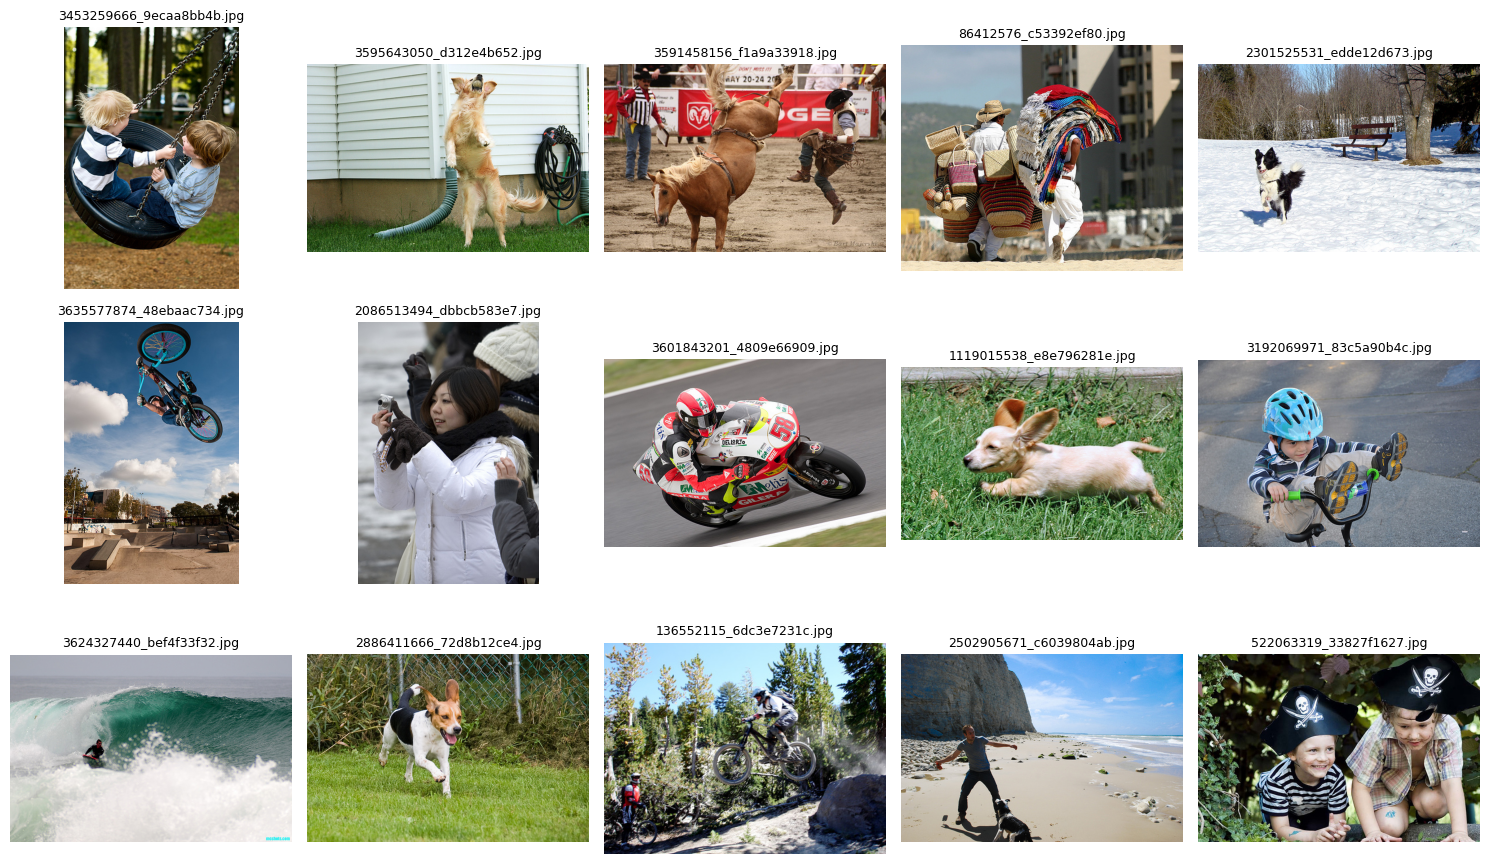

In [125]:
images_to_show = train_data['image'].drop_duplicates().sample(15).tolist()

fig, axes = plt.subplots(3, 5, figsize=(15, 9)) 
axes = axes.ravel()

for i, img_name in enumerate(images_to_show):
    img_path = os.path.join(train_images_path, img_name)
    img = Image.open(img_path)
    axes[i].imshow(img)
    axes[i].set_title(img_name, fontsize=9)
    axes[i].axis('off')

plt.tight_layout()
plt.show()

На изображениях пристуствуют люди или животные, занятые различой деятельностью. Соответственно, комментарии будут касаться изображенных персонажей и того, чем они заняты.

Видим большое количество изображений с детьми. Позднее нужно будет очистить тренировочные данные от таких изображений.

### test_data

In [126]:
test_data = pd.read_csv('/kaggle/input/datasets/tatianaloskutova14/image-search-data/test_queries.csv', sep='|', index_col=0)
test_data.sort_values('image').head(15)

,query_id,query_text,image
0,1177994172_10d143cb8d.jpg#0,"Two blonde boys , one in a camouflage shirt an...",1177994172_10d143cb8d.jpg
1,1177994172_10d143cb8d.jpg#1,Two boys are squirting water guns at each other .,1177994172_10d143cb8d.jpg
2,1177994172_10d143cb8d.jpg#2,Two boys spraying each other with water,1177994172_10d143cb8d.jpg
3,1177994172_10d143cb8d.jpg#3,Two children wearing jeans squirt water at eac...,1177994172_10d143cb8d.jpg
4,1177994172_10d143cb8d.jpg#4,Two young boys are squirting water at each oth...,1177994172_10d143cb8d.jpg
9,1232148178_4f45cc3284.jpg#4,There is a little blond hair girl with a green...,1232148178_4f45cc3284.jpg
7,1232148178_4f45cc3284.jpg#2,A young boy poses for a picture in front of a ...,1232148178_4f45cc3284.jpg
8,1232148178_4f45cc3284.jpg#3,A young girl is smiling in front of the camera...,1232148178_4f45cc3284.jpg
5,1232148178_4f45cc3284.jpg#0,A baby girl playing at a park .,1232148178_4f45cc3284.jpg
6,1232148178_4f45cc3284.jpg#1,A closeup of a child on a playground with adul...,1232148178_4f45cc3284.jpg


In [127]:
test_data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 500 entries, 0 to 499
Data columns (total 3 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   query_id    500 non-null    object
 1   query_text  500 non-null    object
 2   image       500 non-null    object
dtypes: object(3)
memory usage: 15.6+ KB


In [128]:
test_data.duplicated().sum()

np.int64(0)

In [129]:
test_data.nunique()

query_id      500
query_text    500
image         100
dtype: int64

Тестовая выборка по структуре соответствует описанию данных в задании на работу. 100 изображений, по 5 различных комментариев к каждому.

Аналогично тренировочной выборке, очистим тексты от лишних символов и приведем к нижнему регистру.

In [130]:
test_data['query_text'] = test_data['query_text'].apply(clean_text)

### test_images
Загрузим нексколько тестовых изображений.

In [131]:
test_images_path = '/kaggle/input/datasets/tatianaloskutova14/image-search-data/test_images'

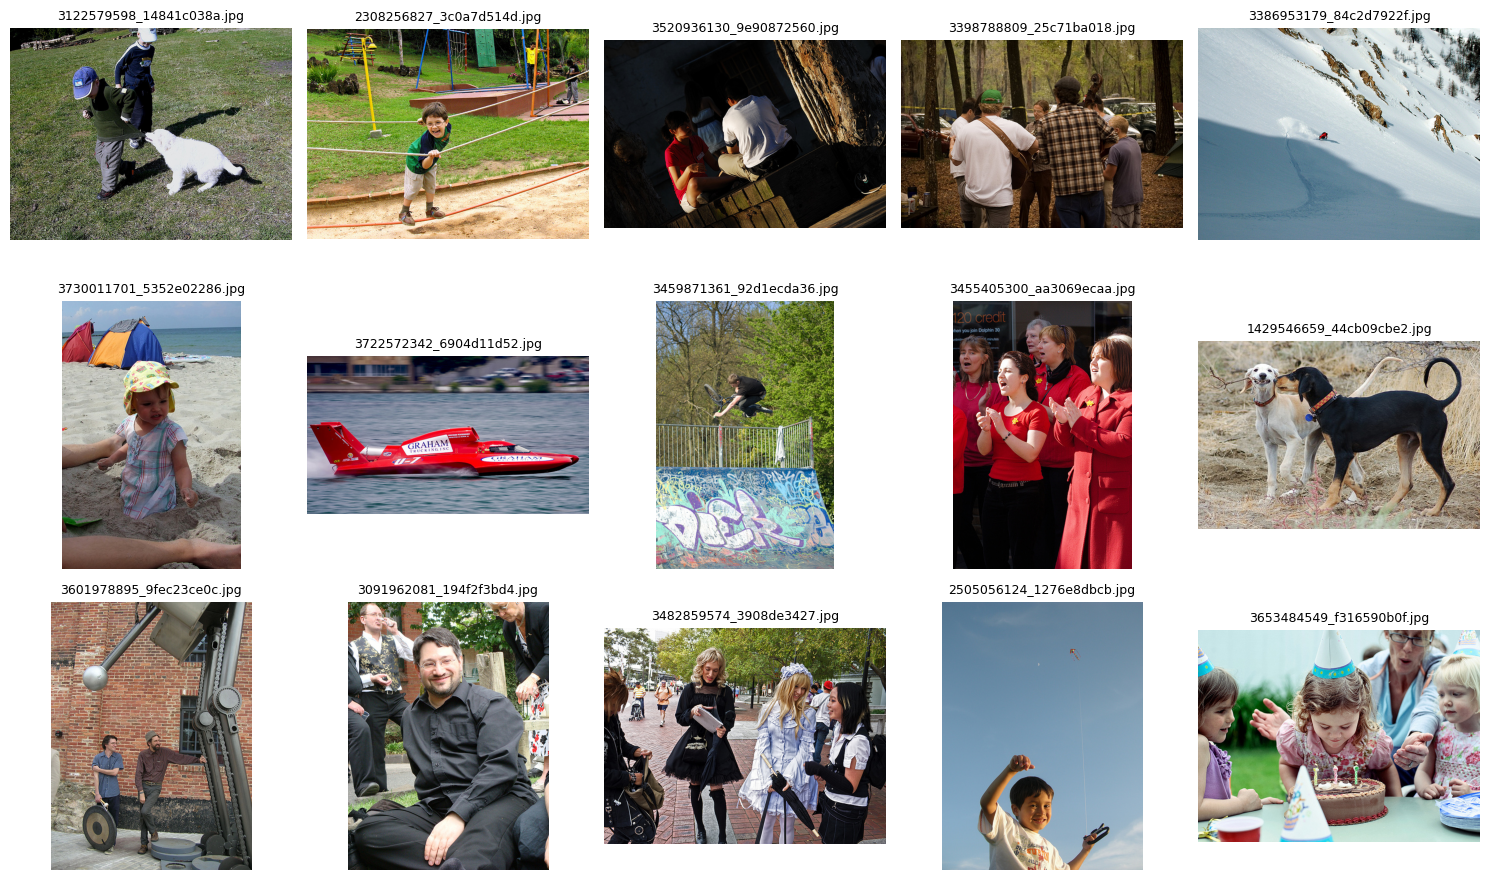

In [132]:
images_to_show_test = test_data['image'].drop_duplicates().sample(15).tolist()

fig, axes = plt.subplots(3, 5, figsize=(15, 9)) 
axes = axes.ravel()

for i, img_name in enumerate(images_to_show_test):
    img_path = os.path.join(test_images_path, img_name)
    img = Image.open(img_path)
    axes[i].imshow(img)
    axes[i].set_title(img_name, fontsize=9)
    axes[i].axis('off')

plt.tight_layout()
plt.show()

Тестовые изображения "однородны" с тренировочными - также видим чем-либо занятых людей и животных.

В тестовой выборке тоже присутствуют изображения детей. Необходимо предусмотреть ограничение на вывод таких изображений моделью.

### crowd
Данные по соответствию изображения и описания, полученные с помощью краудсорсинга.

Столбцы:
- Имя файла изображения.
- Идентификатор описания.
- Доля людей, подтвердивших, что описание соответствует изображению.
- Количество человек, подтвердивших, что описание соответствует изображению.
- Количество человек, подтвердивших, что описание не соответствует изображению.

In [133]:
crowd = pd.read_csv('/kaggle/input/datasets/tatianaloskutova14/image-search-data/CrowdAnnotations.tsv', sep='\t', header=None, names=['image', 'query_id', 'share_positive', 'count_positive', 'count_negative'])
crowd.sort_values('image').head(20)

,image,query_id,share_positive,count_positive,count_negative
0,1056338697_4f7d7ce270.jpg,1056338697_4f7d7ce270.jpg#2,1.000000,3,0
27,1056338697_4f7d7ce270.jpg,3110649716_c17e14670e.jpg#2,0.000000,0,3
28,1056338697_4f7d7ce270.jpg,3143155555_32b6d24f34.jpg#2,0.000000,0,3
29,1056338697_4f7d7ce270.jpg,3192069971_83c5a90b4c.jpg#2,0.000000,0,3
30,1056338697_4f7d7ce270.jpg,3275704430_a75828048f.jpg#2,0.000000,0,3
31,1056338697_4f7d7ce270.jpg,3295680663_af21ea648b.jpg#2,0.000000,0,3
32,1056338697_4f7d7ce270.jpg,3411393875_a9ff73c67a.jpg#2,0.000000,0,3
33,1056338697_4f7d7ce270.jpg,3424424006_98f9d1921c.jpg#2,0.000000,0,3
34,1056338697_4f7d7ce270.jpg,3485425825_c2f3446e73.jpg#2,0.000000,0,3
35,1056338697_4f7d7ce270.jpg,3499720588_c32590108e.jpg#2,0.000000,0,3


In [134]:
crowd.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 47830 entries, 0 to 47829
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   image           47830 non-null  object 
 1   query_id        47830 non-null  object 
 2   share_positive  47830 non-null  float64
 3   count_positive  47830 non-null  int64  
 4   count_negative  47830 non-null  int64  
dtypes: float64(1), int64(2), object(2)
memory usage: 1.8+ MB


In [135]:
crowd[crowd['query_id'].str.contains('#2')].info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 47830 entries, 0 to 47829
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   image           47830 non-null  object 
 1   query_id        47830 non-null  object 
 2   share_positive  47830 non-null  float64
 3   count_positive  47830 non-null  int64  
 4   count_negative  47830 non-null  int64  
dtypes: float64(1), int64(2), object(2)
memory usage: 1.8+ MB


В данном датасете в разы больше, чем в тренировочном датасете, пар изображение+текст. Одному изображению соответствует большое количество комментариев с номером #2. В том числе в данном датасете один из комментариев "родной" - видно из наименования файла и id текста, его share_positive = 1.

In [136]:
crowd[crowd['share_positive'] == 1].count()

image             1323
query_id          1323
share_positive    1323
count_positive    1323
count_negative    1323
dtype: int64

In [137]:
crowd.duplicated().sum()

np.int64(0)

In [138]:
crowd[['image', 'query_id']].duplicated().sum()

np.int64(0)

Дубликатов пар нет.

In [139]:
crowd.nunique()

image             1000
query_id          1000
share_positive      12
count_positive       6
count_negative       7
dtype: int64

В данном датасете уникальных #2-ых комментариев не 977, а все 1000.

In [140]:
(crowd['count_positive'] + crowd['count_negative']).value_counts()

3    46780
4      780
5      220
6       50
Name: count, dtype: int64

Почти все пары в датасете оценивали 3 пользователя. 1050 пар оценили большее количество человек- до 6.

In [141]:
crowd['share_positive'].value_counts()

share_positive
0.000000    41970
0.333333     3000
0.666667     1360
1.000000     1323
0.250000       96
0.500000       27
0.200000       22
0.750000        9
0.600000        8
0.400000        8
0.800000        4
0.166667        3
Name: count, dtype: int64

Ожидаемо, большая часть оценок в датасете - нули, так как пары изображение+текст созданы случайно. 

Посмотрим на распределение ненулевых оценок.

<Axes: >

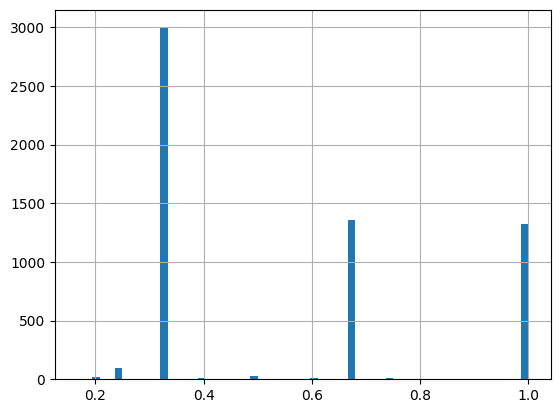

In [142]:
crowd[crowd['share_positive'] != 0]['share_positive'].hist(bins=60)

Так как большая часть пар оценивалась тремя пользователями, оценки 0,33, 0,67 и 1,00 преобладают. Оценка 0,33, когда один из трех пользователей посчитал текст подходящим изображерию, встречается чаще других.

### expert
Данные по соответствию изображения и описания, полученные в результате опроса экспертов. Номера колонок и соответствующий тип данных:
- Имя файла изображения.
- Идентификатор описания.
- 3, 4, 5 — оценки трёх экспертов.

In [143]:
expert = pd.read_csv('/kaggle/input/datasets/tatianaloskutova14/image-search-data/ExpertAnnotations.tsv', sep='\t', header=None, names=['image', 'query_id', 'score_1', 'score_2', 'score_3'])
expert.head(20)

,image,query_id,score_1,score_2,score_3
0,1056338697_4f7d7ce270.jpg,2549968784_39bfbe44f9.jpg#2,1,1,1
1,1056338697_4f7d7ce270.jpg,2718495608_d8533e3ac5.jpg#2,1,1,2
2,1056338697_4f7d7ce270.jpg,3181701312_70a379ab6e.jpg#2,1,1,2
3,1056338697_4f7d7ce270.jpg,3207358897_bfa61fa3c6.jpg#2,1,2,2
4,1056338697_4f7d7ce270.jpg,3286822339_5535af6b93.jpg#2,1,1,2
5,1056338697_4f7d7ce270.jpg,3360930596_1e75164ce6.jpg#2,1,1,1
6,1056338697_4f7d7ce270.jpg,3545652636_0746537307.jpg#2,1,1,1
7,1056338697_4f7d7ce270.jpg,434792818_56375e203f.jpg#2,1,1,2
8,106490881_5a2dd9b7bd.jpg,1425069308_488e5fcf9d.jpg#2,1,1,1
9,106490881_5a2dd9b7bd.jpg,1714316707_8bbaa2a2ba.jpg#2,2,2,2


In [144]:
expert.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5822 entries, 0 to 5821
Data columns (total 5 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   image     5822 non-null   object
 1   query_id  5822 non-null   object
 2   score_1   5822 non-null   int64 
 3   score_2   5822 non-null   int64 
 4   score_3   5822 non-null   int64 
dtypes: int64(3), object(2)
memory usage: 227.6+ KB


In [145]:
expert.duplicated().sum()

np.int64(0)

In [146]:
expert[['image', 'query_id']].duplicated().sum()

np.int64(0)

In [147]:
expert.nunique()

image       1000
query_id     977
score_1        4
score_2        4
score_3        4
dtype: int64

По структуре датасет с оценками экспертов соответствует тренировочному датасету: количество строк, количество уникальных комментариев.

Для каждой строки рассчитаем среднюю оценку экспертов и нормализуем её.

In [148]:
expert['score_mean_norm'] = (expert[['score_1', 'score_2', 'score_3']].mean(axis=1) - 1) / 3
expert.head()

,image,query_id,score_1,score_2,score_3,score_mean_norm
0,1056338697_4f7d7ce270.jpg,2549968784_39bfbe44f9.jpg#2,1,1,1,0.000000
1,1056338697_4f7d7ce270.jpg,2718495608_d8533e3ac5.jpg#2,1,1,2,0.111111
2,1056338697_4f7d7ce270.jpg,3181701312_70a379ab6e.jpg#2,1,1,2,0.111111
3,1056338697_4f7d7ce270.jpg,3207358897_bfa61fa3c6.jpg#2,1,2,2,0.222222
4,1056338697_4f7d7ce270.jpg,3286822339_5535af6b93.jpg#2,1,1,2,0.111111


In [149]:
expert['score_mean_norm'].value_counts()

score_mean_norm
0.000000    2350
0.111111     965
0.222222     689
0.333333     678
0.444444     324
1.000000     247
0.666667     241
0.555556     193
0.777778      75
0.888889      60
Name: count, dtype: int64

<Axes: >

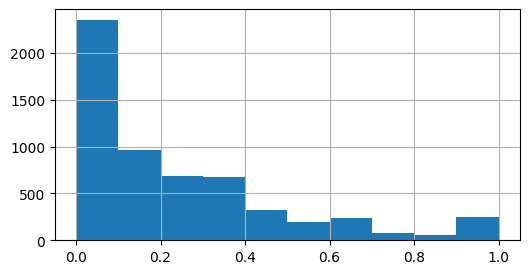

In [150]:
expert['score_mean_norm'].hist(bins=10, figsize=(6,3))

Среди экспертных оценок нулевых 40%. Высоких оценок мало. При этом есть оценки 1.0.

In [151]:
expert[expert['score_mean_norm'] == 1].sample(5)

,image,query_id,score_1,score_2,score_3,score_mean_norm
4170,3458559770_12cf9f134e.jpg,3316725440_9ccd9b5417.jpg#2,4,4,4,1.0
546,1764955991_5e53a28c87.jpg,1764955991_5e53a28c87.jpg#2,4,4,4,1.0
3216,317109978_cb557802e1.jpg,317109978_cb557802e1.jpg#2,4,4,4,1.0
1581,2496370758_a3fbc49837.jpg,327415627_6313d32a64.jpg#2,4,4,4,1.0
3378,3216926094_bc975e84b9.jpg,3216926094_bc975e84b9.jpg#2,4,4,4,1.0


Максимальные оценки от экспертов получали как "родные" пары, так и "неродные".

### Формирование тренировочного df
Объединим полученные данные в один датафрейм. 

Возьмем все имеющиеся пары с оценками (crowd и expert). В crowd бОльшая часть оценок нулевые, но несоответствие текста и картинки - это тоже информация.

*Мы получим существенный дисбаланс по таргету. Ситуация с существенным преобладанием несоответствующих друг другу пар естественна для задачи поиска. При отладке модели пробовался более сбалансированный датасет: все строки из expert (они соответствуют train_data по составу) и строки из crowd только с ненулевыми оценками. Обученная на таком датасете модель работала хуже, чем модель, обученная на большом датасете с дисбалансом.*

В качестве функции для агрегации оценок применим mean() - если есть только одна из оценок, она возьмет её, если обе оценки - посчитает среднее.

In [152]:
merged_scores = expert[['image', 'query_id', 'score_mean_norm']].merge(crowd[['image', 'query_id', 'share_positive']], on=['image', 'query_id'], how='outer')

merged_scores['score_target'] = merged_scores[['score_mean_norm', 'share_positive']].mean(axis=1)

merged_scores.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 51323 entries, 0 to 51322
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   image            51323 non-null  object 
 1   query_id         51323 non-null  object 
 2   score_mean_norm  5822 non-null   float64
 3   share_positive   47830 non-null  float64
 4   score_target     51323 non-null  float64
dtypes: float64(3), object(2)
memory usage: 2.0+ MB


Проверим, как прошло объедиение и агрегация оценок.

In [153]:
merged_scores.sample(10)

,image,query_id,score_mean_norm,share_positive,score_target
20697,2869491449_1041485a6b.jpg,2354540393_a149722680.jpg#2,NaN,0.0,0.0
45257,415793623_6c1225ae27.jpg,447111935_5af98563e3.jpg#2,NaN,0.0,0.0
40970,3585598356_8ce815bbb9.jpg,3688858505_e8afd1475d.jpg#2,NaN,0.0,0.0
50437,791338571_7f38510bf7.jpg,1897025969_0c41688fa6.jpg#2,NaN,0.0,0.0
46324,448658518_eec0b648a6.jpg,3398746625_5199beea71.jpg#2,NaN,0.0,0.0
12355,2450299735_62c095f40e.jpg,2704934519_457dc38986.jpg#2,NaN,0.0,0.0
24051,3006093003_c211737232.jpg,2208310655_a3d83080c5.jpg#2,NaN,0.0,0.0
32444,3287549827_04dec6fb6e.jpg,3359530430_249f51972c.jpg#2,NaN,0.0,0.0
50539,801607443_f15956d1ce.jpg,3609032038_005c789f64.jpg#2,NaN,0.0,0.0
2325,1387785218_cee67735f5.jpg,2343525685_3eba3b6686.jpg#2,NaN,0.0,0.0


In [154]:
merged_scores[['image', 'query_id']].duplicated().sum()

np.int64(0)

In [155]:
merged_scores['score_mean_norm'].count() + merged_scores['share_positive'].count() - merged_scores['score_target'].count()

np.int64(2329)

2329 пар изображение+текст оценивались и краудом, и экспертами. 

Добавим в датафрейм тексты их train_data.

In [156]:
texts_only = train_data[['query_id', 'query_text']].drop_duplicates()
texts_only.sort_values('query_id').head()

,query_id,query_text
5284,1056338697_4f7d7ce270.jpg#2,a woman is signaling is to traffic as seen fro...
3338,106490881_5a2dd9b7bd.jpg#2,a young boy in swimming trunks is walking with...
5808,1082379191_ec1e53f996.jpg#2,a man and a woman sitting on a dock
1564,1084040636_97d9633581.jpg#2,a white dog has its head on the ground
4878,1096395242_fc69f0ae5a.jpg#2,a young boy with his foot outstretched aims a ...


In [157]:
texts_only.nunique()

query_id      977
query_text    977
dtype: int64

In [158]:
train_df = merged_scores.merge(texts_only, on='query_id', how='inner')

train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50214 entries, 0 to 50213
Data columns (total 6 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   image            50214 non-null  object 
 1   query_id         50214 non-null  object 
 2   score_mean_norm  5822 non-null   float64
 3   share_positive   46721 non-null  float64
 4   score_target     50214 non-null  float64
 5   query_text       50214 non-null  object 
dtypes: float64(3), object(3)
memory usage: 2.3+ MB


In [159]:
train_df['query_text'].nunique()

977

Количество строк в df уменьшилось, так как для 1000-977=23 query_id, пристуствоваших в оценках крауда, нет текста в train_data.

Удалим столбцы с оценками крауда и экспертов, оставим только рассчитанный таргет.

In [160]:
train_df = train_df.drop(['score_mean_norm', 'share_positive'], axis=1)
train_df.head()

,image,query_id,score_target,query_text
0,1056338697_4f7d7ce270.jpg,1056338697_4f7d7ce270.jpg#2,1.0,a woman is signaling is to traffic as seen fro...
1,1056338697_4f7d7ce270.jpg,114051287_dd85625a04.jpg#2,0.0,a boy in glasses is wearing a red shirt
2,1056338697_4f7d7ce270.jpg,1427391496_ea512cbe7f.jpg#2,0.0,a young boy holds onto a blue handle on a pier
3,1056338697_4f7d7ce270.jpg,2073964624_52da3a0fc4.jpg#2,0.0,a woman wearing black clothes a purple scarf a...
4,1056338697_4f7d7ce270.jpg,2083434441_a93bc6306b.jpg#2,0.0,an older woman with blond hair rides a bicycle...


Посмотрим на распределение ненулевых оценок в итоговом датафрейме.

np.int64(8567)

<Axes: >

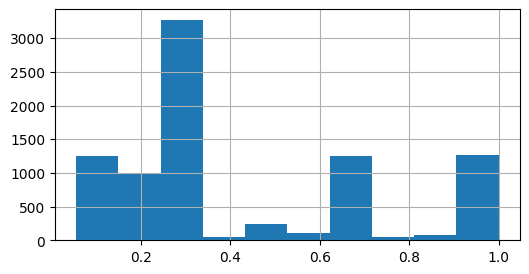

In [161]:
display(train_df[train_df['score_target'] != 0]['score_target'].count())
train_df[train_df['score_target'] != 0]['score_target'].hist(figsize=(6, 3))

Из оценок крауда вошли оценки 0,33, 0,67, 1,00 в большом количестве, добавилось существенное количество оценок 0,11 и 0,22 от экспертов.

## 2. Проверка данных

В некоторых странах, где работает ваша компания, действуют ограничения по обработке изображений: поисковым сервисам и сервисам, предоставляющим возможность поиска, запрещено без разрешения родителей или законных представителей предоставлять любую информацию, в том числе, но не исключительно тексты, изображения, видео и аудио, содержащие описание, изображение или запись голоса детей. Ребёнком считается любой человек, не достигший 16 лет.

В вашем сервисе строго следуют законам стран, в которых работают. Поэтому при попытке посмотреть изображения, запрещённые законодательством, вместо картинок показывается дисклеймер:

> This image is unavailable in your country in compliance with local laws
>

Однако у вас в PoC нет возможности воспользоваться данным функционалом. Поэтому все изображения, которые нарушают данный закон, нужно удалить из обучающей выборки.

**1.** Создадим словарик со словами указывающими на ребенка.

In [162]:
child_keywords = [
    'child', 'children', 'kid', 'kids', 'baby', 'babies',
    'infant', 'infants', 'toddler', 'toddlers',
    'boy', 'boys', 'girl', 'girls',
    'teen', 'teens', 'teenager', 'teenagers',
    'minor', 'minors', 'youngster', 'youngsters',
    'little', 'newborn', 'newborns', 'nursery', 'underage'
]

Найдем в столбце query_text тексты с этими словами.

Сформируем список имен файлов для исключения из обучающей выборки.

Каждому тексту соответствует query_id. Значения в query_id состоят из <имя файла изображения>#<порядковый номер описания>. Выделяем <имя файла изображения>, формируем список.

In [163]:
def has_child_word(text):
    return any(kw in text for kw in child_keywords)

train_df['has_child_keyword'] = train_df['query_text'].apply(has_child_word)
child_texts = train_df[train_df['has_child_keyword']]
child_filenames = set(qid.split('#')[0] for qid in child_texts['query_id'].unique())

len(child_filenames)

296

296 уникальх файлов - почти 30% изображений. Удалим строки с этими именами файлов.

In [164]:
train_df = train_df[~train_df['image'].isin(child_filenames)].reset_index(drop=True)

In [165]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 35551 entries, 0 to 35550
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   image              35551 non-null  object 
 1   query_id           35551 non-null  object 
 2   score_target       35551 non-null  float64
 3   query_text         35551 non-null  object 
 4   has_child_keyword  35551 non-null  bool   
dtypes: bool(1), float64(1), object(3)
memory usage: 1.1+ MB


In [166]:
train_df.nunique()

image                704
query_id             977
score_target          59
query_text           977
has_child_keyword      2
dtype: int64

Кроме изображений, для которых комментарии с упоминанием детей "родные", могут быть изображения, для которых эксперты и/или крауд оценили соответствующим комментарий, упоминающий ребенка.

Выделим строки, где есть упоминание детей и score_target >= 0,5. Выделим наименование файлов, удалим строки эти наименования содержащие.

In [167]:
train_df['has_child_keyword'] = train_df['query_text'].apply(has_child_word)
filtered = train_df[train_df['has_child_keyword'] & (train_df['score_target'] >= 0.5)]
remaining_child_images = filtered['image'].unique().tolist()

len(remaining_child_images)

66

In [168]:
train_df = train_df[~train_df['image'].isin(remaining_child_images)].reset_index(drop=True)

In [169]:
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 31988 entries, 0 to 31987
Data columns (total 5 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   image              31988 non-null  object 
 1   query_id           31988 non-null  object 
 2   score_target       31988 non-null  float64
 3   query_text         31988 non-null  object 
 4   has_child_keyword  31988 non-null  bool   
dtypes: bool(1), float64(1), object(3)
memory usage: 1.0+ MB


In [170]:
train_df.nunique()

image                638
query_id             977
score_target          56
query_text           977
has_child_keyword      2
dtype: int64

В тренировочном датафрейме сохранилось 63,8% фотографий.

Выведем фотографии, оценим результат "очистки" визуально.

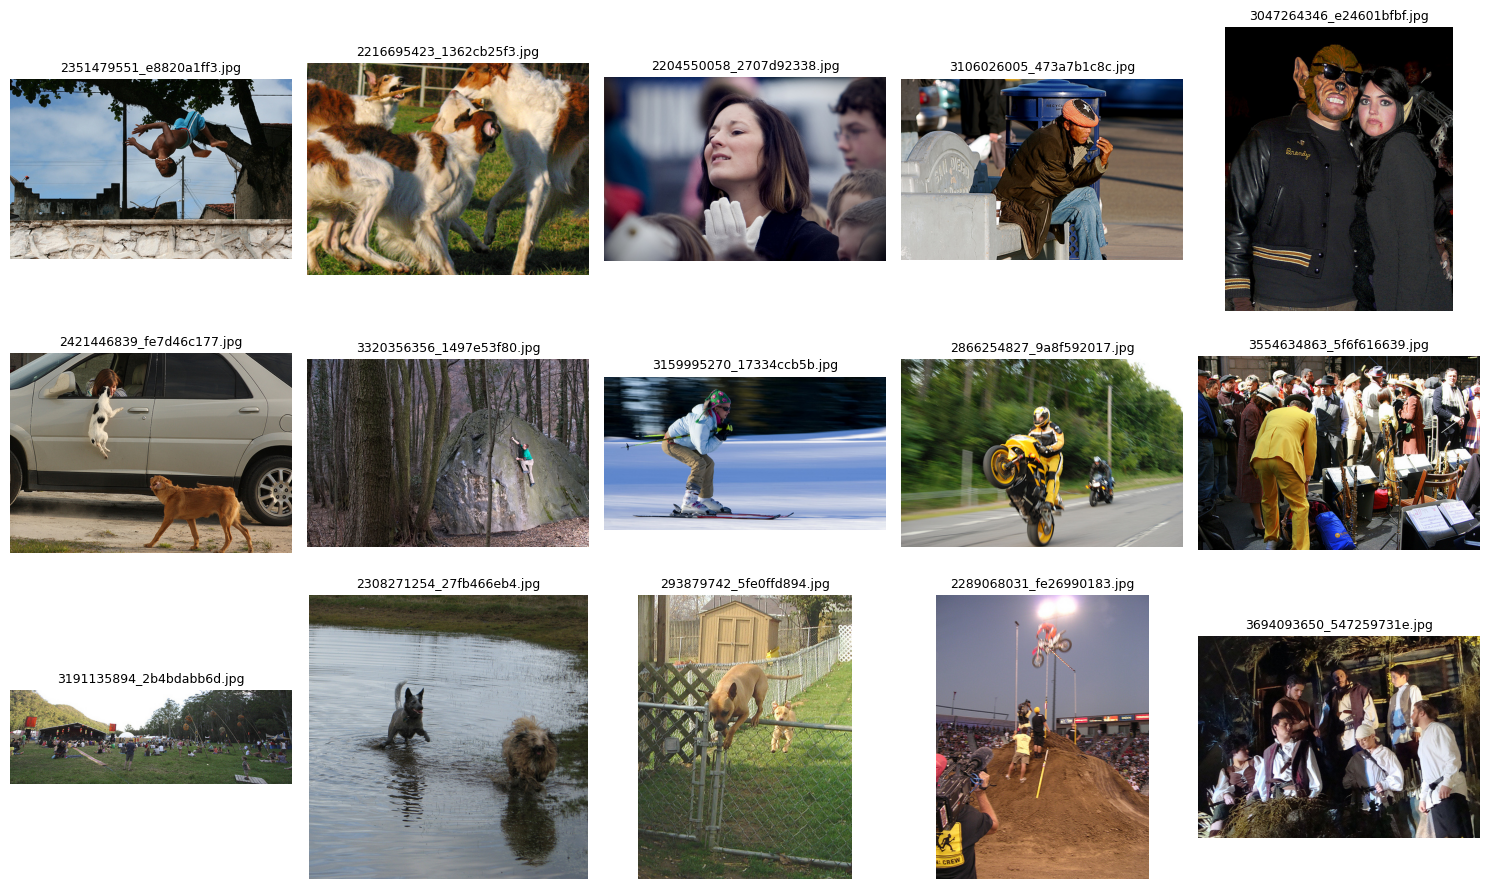

In [171]:
train_images_path = '/kaggle/input/datasets/tatianaloskutova14/image-search-data/train_images'

images_to_show = train_df['image'].drop_duplicates().sample(15).tolist()

fig, axes = plt.subplots(3, 5, figsize=(15, 9)) 
axes = axes.ravel()

for i, img_name in enumerate(images_to_show):
    img_path = os.path.join(train_images_path, img_name)
    img = Image.open(img_path)
    axes[i].imshow(img)
    axes[i].set_title(img_name, fontsize=9)
    axes[i].axis('off')

plt.tight_layout()
plt.show()

В выборках по 15 случайных фотографий дети не обнаружены.

np.int64(5821)

<Axes: >

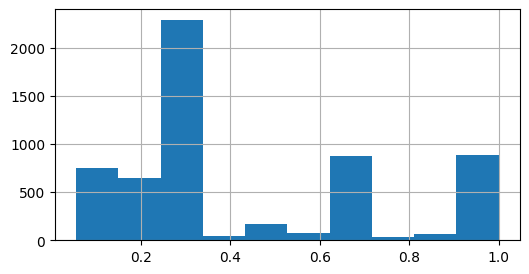

In [172]:
display(train_df[train_df['score_target'] != 0]['score_target'].count())
train_df[train_df['score_target'] != 0]['score_target'].hist(figsize=(6, 3))

Внешиний вид распределения ненулевых оценок не изменился.

## 3. Векторизация изображений

Перейдём к векторизации изображений.

Самый примитивный способ — прочесть изображение и превратить полученную матрицу в вектор. Такой способ нам не подходит: длина векторов может быть сильно разной, так как размеры изображений разные. Поэтому стоит обратиться к свёрточным сетям: они позволяют "выделить" главные компоненты изображений. Как это сделать? Нужно выбрать какую-либо архитектуру, например ResNet-18, посмотреть на слои и исключить полносвязные слои, которые отвечают за конечное предсказание. При этом можно загрузить модель данной архитектуры, предварительно натренированную на датасете ImageNet.

Для векторизации будем использовать предобученную ResNet50.

Загрузим модель без верхнего классификационного слоя.

In [173]:
WEIGHTS_PATH = '/kaggle/input/datasets/tatianaloskutova14/resnet50-weights/resnet50_weights_tf_dim_ordering_tf_kernels_notop.h5'

base_model = ResNet50(
    weights=WEIGHTS_PATH, 
    include_top=False,
    pooling="avg",
    input_shape=(224, 224, 3)
)

In [174]:
base_model.output_shape

(None, 2048)

Создадим функцию, которая извлекает признаки из списка изображений с помощью ResNet50 и возвращает numpy-массив (n_images, 2048).

In [175]:
def extract_image_features(image_paths, model, img_dir, batch_size=64):
    all_features = []
    valid_paths = []

    for img_name in tqdm(image_paths, desc="Extracting image features"):
        img_path = os.path.join(img_dir, img_name)
        try:
            img = keras_image.load_img(img_path, target_size=(224, 224))
            x = keras_image.img_to_array(img)
            x = preprocess_input(x)
            valid_paths.append(x)
        except Exception:
            valid_paths.append(np.zeros((224, 224, 3)))

        if len(valid_paths) == batch_size:
            batch = np.array(valid_paths)
            features = model.predict(batch, verbose=0)
            all_features.append(features)
            valid_paths = []

    if valid_paths:
        batch = np.array(valid_paths)
        features = model.predict(batch, verbose=0)
        all_features.append(features)

    return np.vstack(all_features)

Применим функцию к тренировочной и тестовой выборкам.

In [176]:
train_img_features = extract_image_features(train_df["image"].unique(), base_model, '/kaggle/input/datasets/tatianaloskutova14/image-search-data/train_images')

Extracting image features: 100%|██████████| 638/638 [01:05<00:00,  9.73it/s]


In [177]:
train_img_map = dict(zip(train_df["image"].unique(), train_img_features))

In [178]:
test_img_features = extract_image_features(test_data["image"].unique(), base_model, '/kaggle/input/datasets/tatianaloskutova14/image-search-data/test_images')
test_img_map = dict(zip(test_data["image"].unique(), test_img_features))

Extracting image features: 100%|██████████| 100/100 [00:06<00:00, 14.30it/s]


Собирем матрицы признаков.

In [179]:
train_img_vectors = np.array([train_img_map[name] for name in train_df["image"]])
test_img_vectors = np.array([test_img_map[name] for name in test_data["image"]])

Проверим размерности.

In [180]:
train_img_vectors.shape, test_img_vectors.shape

((31988, 2048), (500, 2048))

## 4. Векторизация текстов

Следующий этап — векторизация текстов. Вы можете поэкспериментировать с несколькими способами векторизации текстов:

- tf-idf
- word2vec
- \*трансформеры (например Bert)

\* — если вы изучали трансформеры в спринте Машинное обучение для текстов.


В силу внешних обстоятельств у нас нет возможности использовать словарь для лемматизации текстов и Bert.

Поэтому для приведения слов к исходным формам применим стемминг, а для векторизации - tf-idf.

In [181]:
stemmer = PorterStemmer()

def apply_stemming(text):
    tokens = text.split()
    stemmed_tokens = [stemmer.stem(token) for token in tokens]
    return ' '.join(stemmed_tokens)

In [182]:
train_df['query_text_'] = train_df['query_text'].apply(apply_stemming)
test_data['query_text'] = test_data['query_text'].apply(apply_stemming)

In [183]:
tf_idf = TfidfVectorizer(
    max_features=5000,      
    ngram_range=(1, 2),     
    stop_words='english',    
    max_df=0.9,
    min_df=2,
)

Обучать tf_idf будем на общем списке текстов, из тренировочной и тестовой выборок. 

Использование тестовой выборки - это утечка данных, в реальных крупных проектах это недопустимо.

В нашей работе мы строим демо-версию приложения, используя очень небольшой объем тренировочных данных и несложный инструмент для векторизации текстов. Поэтому обогатим мешок слов всем "словарным запасом", который нам встретится при тестировании.

*Тестовые запросы, упоминающие детей, не будем использовать.*

In [184]:
test_data_no_child = test_data[~test_data['query_text'].apply(has_child_word)]
test_data_no_child['query_text'].nunique()

337

In [185]:
all_text_unique = (
    pd.concat([train_df[['query_text']], test_data_no_child[['query_text']]])
      .drop_duplicates()
      .reset_index(drop=True)
)

In [186]:
tf_idf.fit(all_text_unique['query_text'].unique())

text_vectors_train = tf_idf.transform(train_df['query_text'])
text_vectors_test  = tf_idf.transform(test_data['query_text'])

Выдедем размерности полученных матриц.

In [187]:
text_vectors_train.shape, text_vectors_test.shape

((31988, 1373), (500, 1373))

## 5. Объединение векторов

Подготовьте данные для обучения: объедините векторы изображений и векторы текстов с целевой переменной.

Чтобы данные были сопоставимы, перед объединением нормализуем матрицы изображений и текстов.

In [188]:
text_normalizer = Normalizer(norm='l2')
img_normalizer = Normalizer(norm='l2')

text_vectors_train = text_normalizer.fit_transform(text_vectors_train)
text_vectors_test = text_normalizer.transform(text_vectors_test)

img_vectors_train = img_normalizer.fit_transform(train_img_vectors)
img_vectors_test = img_normalizer.transform(test_img_vectors)

In [189]:
X_train = hstack([text_vectors_train, csr_matrix(img_vectors_train)]).tocsr()
y_train = train_df['score_target'].values

X_test = hstack([text_vectors_test, csr_matrix(img_vectors_test)]).tocsr()

display(X_train.shape, y_train.shape)
X_test.shape

(31988, 3421)

(31988,)

(500, 3421)

Готовы признаки для обучения моделей.

## 6. Обучение модели предсказания соответствия

Для обучения разделите датасет на тренировочную и тестовую выборки. Простое случайное разбиение не подходит: нужно исключить попадание изображения и в обучающую, и в тестовую выборки.
Для того чтобы учесть изображения при разбиении, можно воспользоваться классом [GroupShuffleSplit](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.GroupShuffleSplit.html) из библиотеки sklearn.model_selection.

Код ниже разбивает датасет на тренировочную и тестовую выборки в пропорции 7:3 так, что строки с одинаковым значением 'group_column' будут содержаться либо в тестовом, либо в тренировочном датасете.

```
from sklearn.model_selection import GroupShuffleSplit
gss = GroupShuffleSplit(n_splits=1, train_size=.7, random_state=42)
train_indices, test_indices = next(gss.split(X=df.drop(columns=['target']), y=df['target'], groups=df['group_column']))
train_df, test_df = df.loc[train_indices], df.loc[test_indices]

```

Какую модель использовать — выберите самостоятельно. Также вам предстоит выбрать метрику качества либо реализовать свою.

Разделим выборки при помощи GroupShuffleSplit с группировкой по train_df['image'].

К тренировочной выборке отнесем 90% данных, оставив для валидации 10%, чтобы обучить модели на максимальном количестве пар.

In [190]:
gss = GroupShuffleSplit(n_splits=1, train_size=0.9, random_state=RANDOM_STATE)
train_indices, val_indices = next(gss.split(X=X_train, y=y_train, groups=train_df['image']))

X_tr = X_train[train_indices]
X_val = X_train[val_indices]
y_tr = y_train[train_indices]
y_val = y_train[val_indices]

X_tr.shape, X_val.shape

((29108, 3421), (2880, 3421))

Попробуем два варианта модели: простую - линейную регрессию и полносвязную нейронную сеть.

Сравнивать модели будем по значению метрики RMSE на валидационной выборке.

### Линейная регрессия

In [191]:
lr_model = LinearRegression()
lr_model.fit(X_tr, y_tr)

y_pred_lr = lr_model.predict(X_val)

Так как таргет находится в интервале [0, 1], предсказания необходимо нормализовать.

In [192]:
def normalize_scores(scores):
    min_val = np.min(scores)
    max_val = np.max(scores)
    if min_val == max_val:
        return np.zeros_like(scores)  
    return (scores - min_val) / (max_val - min_val)

In [193]:
y_pred_lr_normalized = normalize_scores(y_pred_lr)

Рассчитаем значение метрики.

In [194]:
mse_lr = mean_squared_error(y_val, y_pred_lr_normalized)
rmse_lr = np.sqrt(mse_lr)
round(rmse_lr, 4)

np.float64(0.3273)

### Полносвязная нейронная сеть - Keras

Для подачи нейронной сети преобразуем разреженные матрицы в плотные numpy-массивы.

In [195]:
X_train_dense = X_train.toarray()
X_test_dense = X_test.toarray()
X_tr_dense = X_tr.toarray()
X_val_dense = X_val.toarray()

Создадим последовательную модель нейронной сети:
- Input layer: принимает данные размерности input_dim;
- Dense layers: полносвязные слои с ReLU активацией, регуляризацией, dropout;
- Output layer: 1 нейрон - линейный выход.

In [196]:
input_dim = X_train_dense.shape[1]

l2_reg = 1e-5

nn_model = Sequential([
    Input(shape=(input_dim,)),
    
    Dense(512, activation="relu", kernel_regularizer=regularizers.l2(l2_reg)),
    Dropout(0.2),
    
    Dense(256, activation="relu", kernel_regularizer=regularizers.l2(l2_reg)),
    Dropout(0.2),
    
    Dense(128, activation="relu", kernel_regularizer=regularizers.l2(l2_reg)),
    Dropout(0.1),
    
    Dense(1) 
])

В качестве функции потерь применим weighted_mse, которая позволит лучше обучить модель на строках с положительным таргетом.

In [260]:
def root_mean_squared_error(y_true, y_pred):
    return tf.math.sqrt(tf.keras.backend.mean(tf.keras.backend.square(y_pred - y_true)))

def weighted_mse(y_true, y_pred):
    weights = tf.where(y_true > 0, 5.0, 1.0)  
    return tf.keras.backend.mean(weights * tf.keras.backend.square(y_pred - y_true))

nn_model.compile(
    optimizer=Adam(learning_rate=1e-4),
    loss=weighted_mse,              
    metrics=[root_mean_squared_error]
)

nn_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_4 (Dense)                 │ (None, 512)            │     1,752,064 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,916,417 (7.31 MB)

 Trainable params: 1,916,417 (7.31 MB)

 Non-trainable params: 0 (0.00 B)

Обучим построенную модель. Будем обучать на 30 эпохах с ранней остановкой.

In [261]:
early_stop = callbacks.EarlyStopping(
    monitor='val_loss',
    patience=7,
    restore_best_weights=True,
    verbose=1
)

history = nn_model.fit(
    X_tr_dense, y_tr,
    validation_data=(X_val_dense, y_val),
    epochs=30,
    batch_size=64,
    callbacks=[early_stop],
    verbose=1
)

val_loss, val_rmse = nn_model.evaluate(X_val_dense, y_val, verbose=0)
print(f"Val RMSE: {val_rmse:.4f}")

Epoch 1/30
455/455 ━━━━━━━━━━━━━━━━━━━━ 11s 21ms/step - loss: 0.0748 - root_mean_squared_error: 0.2861 - val_loss: 0.1407 - val_root_mean_squared_error: 0.2150
Epoch 2/30
455/455 ━━━━━━━━━━━━━━━━━━━━ 9s 20ms/step - loss: 0.0645 - root_mean_squared_error: 0.2869 - val_loss: 0.1340 - val_root_mean_squared_error: 0.2367
Epoch 3/30
455/455 ━━━━━━━━━━━━━━━━━━━━ 9s 20ms/step - loss: 0.0577 - root_mean_squared_error: 0.2872 - val_loss: 0.1381 - val_root_mean_squared_error: 0.2286
Epoch 4/30
455/455 ━━━━━━━━━━━━━━━━━━━━ 9s 20ms/step - loss: 0.0519 - root_mean_squared_error: 0.2881 - val_loss: 0.1382 - val_root_mean_squared_error: 0.2268
Epoch 5/30
455/455 ━━━━━━━━━━━━━━━━━━━━ 9s 20ms/step - loss: 0.0479 - root_mean_squared_error: 0.2874 - val_loss: 0.1334 - val_root_mean_squared_error: 0.2305
Epoch 6/30
455/455 ━━━━━━━━━━━━━━━━━━━━ 9s 20ms/step - loss: 0.0456 - root_mean_squared_error: 0.2891 - val_loss: 0.1351 - val_root_mean_squared_error: 0.2280
Epoch 7/30
455/455 ━━━━━━━━━━━━━━━━━━━━ 9s 20

Сравненим модели по значению метрики на валидационной выборке:
- Линейная регрессия - RMSE = 0.3273
- Нейронная сеть - RMSE = 0.2242

Тестировать будем нейронную сеть.

## 7. Тестирование модели

Настало время протестировать модель. Для этого получите эмбеддинги для всех тестовых изображений из папки `test_images`, выберите случайные 10 запросов из файла `test_queries.csv` и для каждого запроса выведите наиболее релевантное изображение. Сравните визуально качество поиска.

In [262]:
test_data_original = pd.read_csv('/kaggle/input/datasets/tatianaloskutova14/image-search-data/test_queries.csv', sep='|', index_col=0)

Выбираем 10 случайных комментариев.

In [263]:
np.random.seed()
sample_indices = np.random.choice(len(test_data), size=10, replace=False)
sample_indices

array([385, 313, 182, 316,  57, 139, 164, 295,  84, 207])

При помощи цикла для каждого комментария рассчитаем оценку сходства с каждым изображением (таргет). Выведем изображения с наибольшим значением таргета.

'Запрос: A man and a woman are sitting on a bench outside a wooden building .'

'Подобранное изображение: 3030079705_0dee8a3e89.jpg (score: 0.4469)'

'Максимальная оценка: 0.4469.'

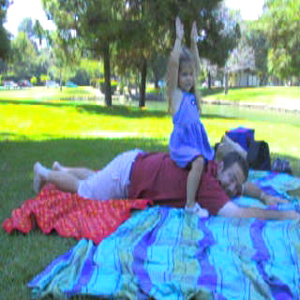

----------------------------------------------------------------------------------------------------



'Запрос: a young boy jump off a rock in the forest'

'Предоставление изображений с участием детей ограничено'

'----------------------------------------------------------------------------------------------------\n'

'Запрос: A woman works by a sewing machine .'

'Подобранное изображение: 3036971334_78187a9570.jpg (score: 0.7217)'

'Максимальная оценка: 0.7217.'

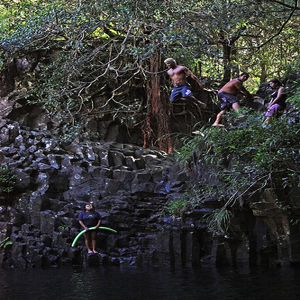

----------------------------------------------------------------------------------------------------



'Запрос: A group of people perform together onstage .'

'Подобранное изображение: 269650644_059a84ece5.jpg (score: 0.5776)'

'Максимальная оценка: 0.5776.'

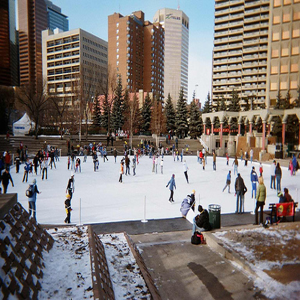

----------------------------------------------------------------------------------------------------



'Запрос: a littl kid hold up a remot control in front of the televis'

'Предоставление изображений с участием детей ограничено'

'----------------------------------------------------------------------------------------------------\n'

'Запрос: three littl boy stand next to and on a fenc'

'Предоставление изображений с участием детей ограничено'

'----------------------------------------------------------------------------------------------------\n'

'Запрос: Two puppies jump from a concrete slab onto the grass .'

'Подобранное изображение: 3466891862_9afde75568.jpg (score: 0.5478)'

'Максимальная оценка: 0.5478.'

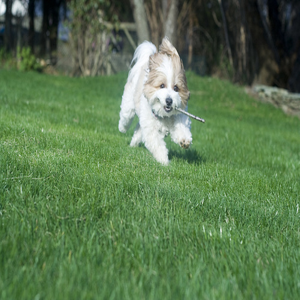

----------------------------------------------------------------------------------------------------



'Запрос: a family standing in a rock cave with some of their belongings in the background'

'Подобранное изображение: 3044745642_1d0784ff29.jpg (score: 0.3539)'

'Максимальная оценка: 0.3539.'

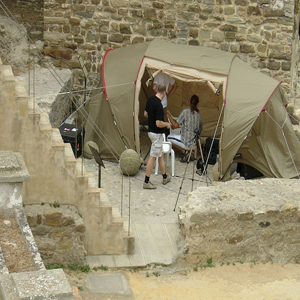

----------------------------------------------------------------------------------------------------



'Запрос: the littl boy is smile as he cross a rope on an assault cours'

'Предоставление изображений с участием детей ограничено'

'----------------------------------------------------------------------------------------------------\n'

"Запрос: Four people are cavorting on the rocks at a river 's edge"

'Подобранное изображение: 3555573680_41c1540a86.jpg (score: 0.4357)'

'Максимальная оценка: 0.4357.'

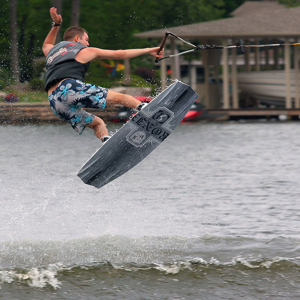

----------------------------------------------------------------------------------------------------



In [264]:
all_test_images_ordered = test_data['image'].tolist()

#clip_min, clip_max = 0.0, 1.0

for idx in sample_indices:
    row = test_data.iloc[idx]
    query_text = row['query_text']
    row_original = test_data_original.iloc[idx]
    query_text_original = row_original['query_text']

    if has_child_word(query_text):
        display(f'Запрос: {query_text}')
        display('Предоставление изображений с участием детей ограничено')
        display('-' * 100 + '\n')
        continue
    
    query_vec = text_vectors_test[idx]
    
    query_repeated = np.repeat(query_vec.toarray(), len(img_vectors_test), axis=0)
    
    X_test = hstack([
        csr_matrix(query_repeated),
        img_vectors_test
    ]).tocsr()
    
    #scores_raw = nn_model.predict(X_test.toarray(), verbose=0).ravel()

    #scores = np.clip(scores_raw, clip_min, clip_max)

    scores = nn_model.predict(X_test.toarray(), verbose=0).ravel()
    
    best_idx = np.argmax(scores)
    best_image = all_test_images_ordered[best_idx]
    best_score = scores[best_idx]
    
    display(f'Запрос: {query_text_original}')
    display(f'Подобранное изображение: {best_image} (score: {best_score:.4f})')
    display(f'Максимальная оценка: {scores.max():.4f}.')
    
    try:
        img_path = os.path.join(test_images_path, best_image)
        img = Image.open(img_path).resize((300, 300))
        display(img)
    except Exception as e:
        print(f'Ошибка при отображении изображения: {e}')

    print('-' * 100 + '\n')

В ячейке с выбором 10 случайных запросов np.random.seed() специальное не зафиксирован RANDOM_STATE для удобства экспериментирования.

Многократно сформировав подвыборки по 10 комментариев и подобрав к ним изображения, можем сказать следующее: 
1. **Модель очень хорошо отличает собак от людей**.
2. Также **определяет цвета, видит снег, воду, горы, траву**.
3. Что касается действий, выполняемых людьми - с этим хуже. Неудивительно, ведь действия людей сложны и многообразны, а обучающая выборка не так велика.

I. Прокомментируем изображения к случайному запросу выше, где **5 комментариев про людей**, 1 про собаку:
  - A man and a woman are sitting on a bench outside a wooden building - **вместо женщины девочка - на фотографиях с детьми модель не обучалась**;
  - A woman works by a sewing machine - **совсем нет**;
  - A group of people perform together onstage - **каток похож очень на сцену**;
  - Two puppies jump from a concrete slab onto the grass - **щенок прыгает на траву, но только один**;
  - a family standing in a rock cave with some of their belongings in the background - **есть каменные стены - пещера, есть люди, есть вещи**;
  - Four people are cavorting on the rocks at a river 's edge - **река есть, один человек резвится**

II. В качестве альтернативного примера прокомментируем изображения, подобранные для запроса, в который случайным образом попали **5 комментариев с собаками** (4 с детьми - они не были отображены). *При сохранении версии с перезапуском кода менятся подборка из 10 случайных комментариев, поэтому запрос не сохранился.*

  - a little white and tan dog running through the grass with a stick in his mouth - **точное попадание**;
  - The black dog has a toy in its mouth and a person stands nearby - **собака не полностью, но частично черная, человека нет**;
  - A man demonstrating how high his black dog can jump - **черная собака есть, даже две, но вторая плохо различима**;
  -  A black and white dog with a chunk of snow it its mouth while walking on a snowy surface - **точное попадание**;
  -  a couple each wearing a silly mask and holding a fake cigar - **не пара, а тройка, в шлемах))) - совсем не попали**;
  -  Two black dogs are playing tug-of-war with an orange toy - **две собаки есть (правда, одна белая), оранжевая игрушка есть**.

## 8. Выводы

**1.** При подготовке к выполнению работы полученные **данные были осмотрены и проверены на соответствие описанию. Выявлено:**
- В train_data входит 1000 уникальных изображений и 977 уникальных пар, состоящих из текста и его id. В датасете создано 5822 комбинации изображение+текст, вероятнее всего, случайным образом. В датасет включены только комментарии с номером #2.
- Тестовая выборка по структуре соответствует описанию данных в задании на работу. 100 изображений, по 5 различных комментариев к каждому.
- На изображениях тренировочной и тестовой выборок пристуствуют люди или животные, занятые различой деятельностью. Комментарии касаются изображенных персонажей и того, чем они заняты.
- В данных по соответствию изображения и описания, полученных с помощью краудсорсинга, строк в разы больше, чем в тренировочном датасете. Одному изображению соответствует большое количество комментариев с номером #2. Ожидаемо, большая часть оценок в датасете - нули, так как пары изображение+текст созданы случайно. Среди ненулевых оценок преобладают 0,33, 0,67 и 1,00, так как преобладающая часть пар оценивалась 3 пользователями.
- Датасет с оценками экспертов по структуре соответствует тренировочному датасету: количество строк, количество уникальных комментариев. Для каждой строки была рассчитана и нормализована к [0, 1] средняя оценка экспертов. Нулевых значений получилось 40%, высоких средних оценок мало.

**2. Тренировочный датасет был сформирован следующим образом.** Объединены все имеющиеся пары с оценками (crowd и expert). В crowd бОльшая часть оценок нулевые, но несоответствие текста и картинки - это тоже информация.

*Мы получим существенный дисбаланс по таргету. Ситуация с существенным преобладанием несоответствующих друг другу пар естественна для задачи поиска. При отладке модели пробовался более сбалансированный датасет: все строки из expert (они соответствуют train_data по составу) и строки из crowd только с ненулевыми оценками. Обученная на таком датасете модель работала хуже, чем модель, обученная на большом датасете с дисбалансом.*

В качестве функции для агрегации оценок применена mean() - для пар, где есть только одна из оценок, она взяла её, где есть оценки - рассчитала среднее.

**3.** В некоторых странах действуют **ограничения по обработке изображений с детьми**. Был создан словарик, помогающий найти в текстах комметариев упоминание ребенка. Из тренировочной выборки были удалены все изображения для которых "родным" является комментарий, упоминающий ребенка ("родство" определено по соответствию наименований файлов и id текстов), а также удалены изображения, для которых комментарий, упоминающие детей, оценены соответствующими на 0,5 и более.

**4. Для векторизации изображений применена предобученная ResNet50 без верхнего классификационного слоя.**

**5.** Для приведения слов в запросах к исходным формам применим стемминг, а **для векторизации текстов - TF-IDF**. В силу внешних обстоятельств у нас нет возможности использовать словарь для лемматизации текстов и Bert.

**6.** Чтобы данные были сопоставимы, перед объединением **матрицы изображений и текстов были нормализованы**.

**7.** Тренировочная и валидационная выборка сформированы в соотношении 90%/10%, чтобы обучить модели на максимальном количестве пар. Применен GroupShuffleSplit с группировкой по train_df['image'].

**8.** Обучено два варианта модели: простая - линейная регрессия, полносвязная нейронная сеть.

Модели сравнивались по значению метрики RMSE на валидационной выборке.
- Линейная регрессия - RMSE = 0.3273
- **Нейронная сеть - RMSE = 0.2370**

Нейронная сеть имеет следующую структуру:
  - Input layer: принимает данные размерности input_dim;
  - Dense layers: полносвязные слои с ReLU активацией, регуляризацией, dropout;
  - Output layer: 1 нейрон - линейный выход.

В качестве функции потерь применена weighted_mse, которая позволила лучше обучить модель на строках с положительным таргетом.

**9. Для тестирование нейронной сети** требовалось выбрать случайные 10 комментариев из файла test_queries.csv и для каждого комментария вывести наиболее релевантное изображение, сравнить визуально качество поиска.

Многократно сформировав подвыборки по 10 комментариев и подобрав к ним изображения, можем сказать следующее:

- **Модель очень хорошо отличает собак от людей.**
- **Модель определяет цвета, видит снег, воду, горы, траву.**
- Действия, выполняемые людьми, модель определяем хуже. Неудивительно, ведь действия людей сложны и многообразны, а обучающая выборка не так велика.

Подготовленная **версия модели для поиска изображений по запросу явлется демострационной, она применяет несложные инструменты, обучена на данных небольшого объема и унифицированного содержания** (на всех изображениях люди или собаки, комментарии описывают персонажей и их действия). При применении более сложных моделей, больших мощностей и обработке обширных данных возможно получить модель существенно более высокого качества.

- [x]  Jupyter Notebook открыт
- [x]  Весь код выполняется без ошибок
- [x]  Ячейки с кодом расположены в порядке исполнения
- [x]  Исследовательский анализ данных выполнен
- [x]  Проверены экспертные оценки и краудсорсинговые оценки
- [x]  Из датасета исключены те объекты, которые выходят за рамки юридических ограничений
- [x]  Изображения векторизованы
- [x]  Текстовые запросы векторизованы
- [x]  Данные корректно разбиты на тренировочную и тестовую выборки
- [x]  Предложена метрика качества работы модели
- [x]  Предложена модель схожести изображений и текстового запроса
- [x]  Модель обучена
- [x]  По итогам обучения модели сделаны выводы
- [x]  Проведено тестирование работы модели
- [x]  По итогам тестирования визуально сравнили качество поиска